# Projet 2 — Classification de gestes de la main
## Comprendre le dataset et la logique du prétraitement

**Objectif de ce notebook :** comprendre les images du dataset Rock Paper Scissors, observer leur représentation numérique, construire un échantillon équilibré de 900 images, puis préparer les ensembles `train`, `validation` et `test`.

> Ce notebook s'arrête à la préparation des données. Il ne contient pas encore l'entraînement de k-NN, Softmax ou CNN.

### Résultat attendu

- 3 classes : `rock`, `paper`, `scissors`
- 300 images par classe, soit 900 images
- Images RGB de taille `32 × 32 × 3`
- Découpage stratifié : 60 % entraînement, 20 % validation, 20 % test
- Les mêmes partitions pourront ensuite être utilisées pour comparer les trois modèles.


## 0. Préparer l'environnement

Nous utiliserons :
- **TensorFlow Datasets (TFDS)** pour télécharger le dataset officiel ;
- **NumPy** pour manipuler les tableaux numériques ;
- **Matplotlib** pour visualiser les images ;
- **scikit-learn** pour effectuer un découpage stratifié.

Si ces bibliothèques ne sont pas installées dans votre environnement, exécutez la cellule suivante.

In [25]:
%pip install -q tensorflow tensorflow-datasets numpy matplotlib scikit-learn

Note: you may need to restart the kernel to use updated packages.


## 1. Importer les bibliothèques

Chaque bibliothèque a un rôle précis. Prenez le temps de lire les commentaires : il est important de savoir pourquoi nous l'utilisons.

In [26]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_datasets as tfds

from collections import Counter
from sklearn.model_selection import train_test_split

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow :", tf.__version__)
print("TensorFlow Datasets :", tfds.__version__)

TensorFlow : 2.21.0
TensorFlow Datasets : 4.9.10


## 2. Découvrir le dataset Rock Paper Scissors

Le dataset contient des photographies de mains réalisant les gestes du jeu :
- `rock` : poing fermé ;
- `paper` : main ouverte ;
- `scissors` : deux doigts ouverts.

Une image est une observation. Son **label** (étiquette) indique la classe à laquelle elle appartient.

Nous chargeons ici les partitions officielles `train` et `test` ensemble, uniquement pour constituer l'échantillon expérimental imposé par le sujet. Nous créerons ensuite nos propres partitions 60/20/20. Ainsi, nous ne conserverons pas le découpage officiel du dataset.

In [27]:
# Télécharger et charger les deux partitions du dataset.
# as_supervised=True renvoie directement (image, label).
(ds_train, ds_test), info = tfds.load(
    "rock_paper_scissors",
    split=["train", "test"],
    as_supervised=True,
    with_info=True
)

print(info)
print("\nClasses :", info.features["label"].names)
print("Nombre d'images train TFDS :", info.splits["train"].num_examples)
print("Nombre d'images test TFDS  :", info.splits["test"].num_examples)

tfds.core.DatasetInfo(
    name='rock_paper_scissors',
    full_name='rock_paper_scissors/3.0.0',
    description="""
    Images of hands playing rock, paper, scissor game.
    """,
    homepage='http://laurencemoroney.com/rock-paper-scissors-dataset',
    data_dir='/Users/ayoub/tensorflow_datasets/rock_paper_scissors/3.0.0',
    file_format=tfrecord,
    download_size=219.53 MiB,
    dataset_size=219.23 MiB,
    features=FeaturesDict({
        'image': Image(shape=(300, 300, 3), dtype=uint8),
        'label': ClassLabel(shape=(), dtype=int64, num_classes=3),
    }),
    supervised_keys=('image', 'label'),
    disable_shuffling=False,
    nondeterministic_order=False,
    splits={
        'test': <SplitInfo num_examples=372, num_shards=1>,
        'train': <SplitInfo num_examples=2520, num_shards=2>,
    },
    citation="""@ONLINE {rps,
    author = "Laurence Moroney",
    title = "Rock, Paper, Scissors Dataset",
    month = "feb",
    year = "2019",
    url = "http://laurencemoroney.c

### 2.1 Comprendre les labels

Un ordinateur manipule des nombres, pas les mots `rock`, `paper` ou `scissors`. TFDS associe donc un identifiant entier à chaque classe.

La cellule suivante affiche explicitement cette correspondance. **Ne supposez jamais l'ordre des classes : vérifiez-le dans les métadonnées du dataset.**

In [28]:
class_names = info.features["label"].names
label_to_name = {i: name for i, name in enumerate(class_names)}

for label_id, class_name in label_to_name.items():
    print(f"{label_id} -> {class_name}")

0 -> rock
1 -> paper
2 -> scissors


## 3. Observer une image avant tout prétraitement

Nous récupérons quelques exemples pour examiner leur contenu. Une image couleur est généralement représentée par un tableau de forme :

`hauteur × largeur × canaux`

Pour une image RGB, les trois canaux sont Rouge (R), Vert (G) et Bleu (B).

Type de l'image : <class 'tensorflow.python.framework.ops.EagerTensor'>
Dimensions : (300, 300, 3)
Type numérique : <dtype: 'uint8'>
Label numérique : 2
Nom de la classe : scissors


W0000 00:00:1793442994.511788 5621928 cache_dataset_ops.cc:912] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


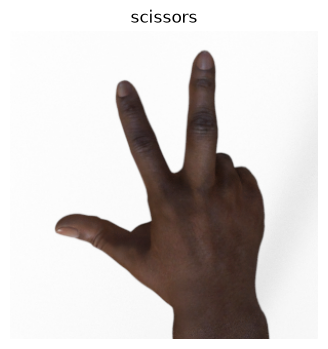

In [29]:
# Récupérer un exemple depuis le dataset.
example_image, example_label = next(iter(ds_train))

print("Type de l'image :", type(example_image))
print("Dimensions :", example_image.shape)
print("Type numérique :", example_image.dtype)
print("Label numérique :", int(example_label.numpy()))
print("Nom de la classe :", label_to_name[int(example_label.numpy())])

plt.figure(figsize=(4, 4))
plt.imshow(example_image.numpy())
plt.title(label_to_name[int(example_label.numpy())])
plt.axis("off")
plt.show()

### À comprendre

- `shape` indique le nombre de lignes, de colonnes et de canaux.
- `dtype` indique le type des valeurs des pixels.
- `label` est la réponse attendue pour cette image.
- `plt.imshow` transforme les valeurs numériques en affichage visuel.

**Question de réflexion :** si deux images montrent le même geste mais que la main est tournée différemment, leurs tableaux de pixels seront-ils identiques ? Pourquoi ?

## 4. Examiner la distribution des classes

Avant de construire notre échantillon, vérifions combien d'images sont disponibles pour chaque classe dans les deux partitions réunies.

In [30]:
# Convertir les exemples TFDS en tableaux NumPy.
all_images = []
all_labels = []

for dataset in [ds_train, ds_test]:
    for image, label in tfds.as_numpy(dataset):
        all_images.append(image)
        all_labels.append(int(label))

all_images = np.array(all_images, dtype=object)
all_labels = np.array(all_labels, dtype=np.int64)

print("Nombre total d'images :", len(all_images))
print("Nombre total de labels :", len(all_labels))

counts = Counter(all_labels)
for label_id, count in sorted(counts.items()):
    print(f"{label_to_name[label_id]} : {count}")

Nombre total d'images : 2892
Nombre total de labels : 2892
rock : 964
paper : 964
scissors : 964


### 4.1 Visualiser la distribution

Un dataset équilibré contient le même nombre d'observations dans chaque classe. Le sujet impose 300 images par classe.

Si une classe possède beaucoup plus d'images qu'une autre, un modèle pourrait favoriser la classe majoritaire. Ici, nous allons construire volontairement un échantillon équilibré.

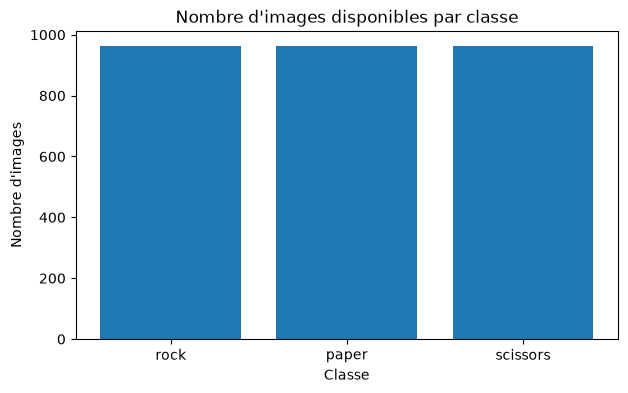

In [31]:
class_counts = [counts[i] for i in range(len(class_names))]

plt.figure(figsize=(7, 4))
plt.bar(class_names, class_counts)
plt.title("Nombre d'images disponibles par classe")
plt.xlabel("Classe")
plt.ylabel("Nombre d'images")
plt.show()

## 5. Construire un échantillon équilibré : 300 images par classe

Nous sélectionnons aléatoirement 300 images pour chacune des trois classes.

Pourquoi utiliser une graine (`SEED`) ? Pour rendre la sélection reproductible : en relançant le notebook avec la même graine et les mêmes données, nous obtenons la même sélection.

Attention : nous ne choisissons pas les images en fonction de leur apparence ou de leur difficulté. La sélection est aléatoire.

In [32]:
N_PER_CLASS = 300
selected_indices = []

for label_id in range(len(class_names)):
    # Indices des images appartenant à la classe courante.
    class_indices = np.where(all_labels == label_id)[0]

    if len(class_indices) < N_PER_CLASS:
        raise ValueError(
            f"Pas assez d'images pour {label_to_name[label_id]} : "
            f"{len(class_indices)} disponibles."
        )

    # Tirage aléatoire de 300 indices sans répétition.
    chosen = np.random.choice(
        class_indices,
        size=N_PER_CLASS,
        replace=False
    )
    selected_indices.extend(chosen)

# Mélanger les indices sélectionnés pour ne pas regrouper les classes.
selected_indices = np.array(selected_indices)
np.random.shuffle(selected_indices)

X_selected = np.stack([all_images[i] for i in selected_indices])
y_selected = all_labels[selected_indices]

print("X_selected :", X_selected.shape)
print("y_selected :", y_selected.shape)
print("Distribution :", {
    label_to_name[i]: int(np.sum(y_selected == i))
    for i in range(len(class_names))
})

X_selected : (900, 300, 300, 3)
y_selected : (900,)
Distribution : {'rock': 300, 'paper': 300, 'scissors': 300}


In [33]:
X_selected = np.array(X_selected).astype(np.uint8)

### 5.1 Vérifier visuellement l'échantillon

Affichons quelques images de chaque classe. L'objectif est de vérifier que les labels correspondent bien aux gestes représentés.

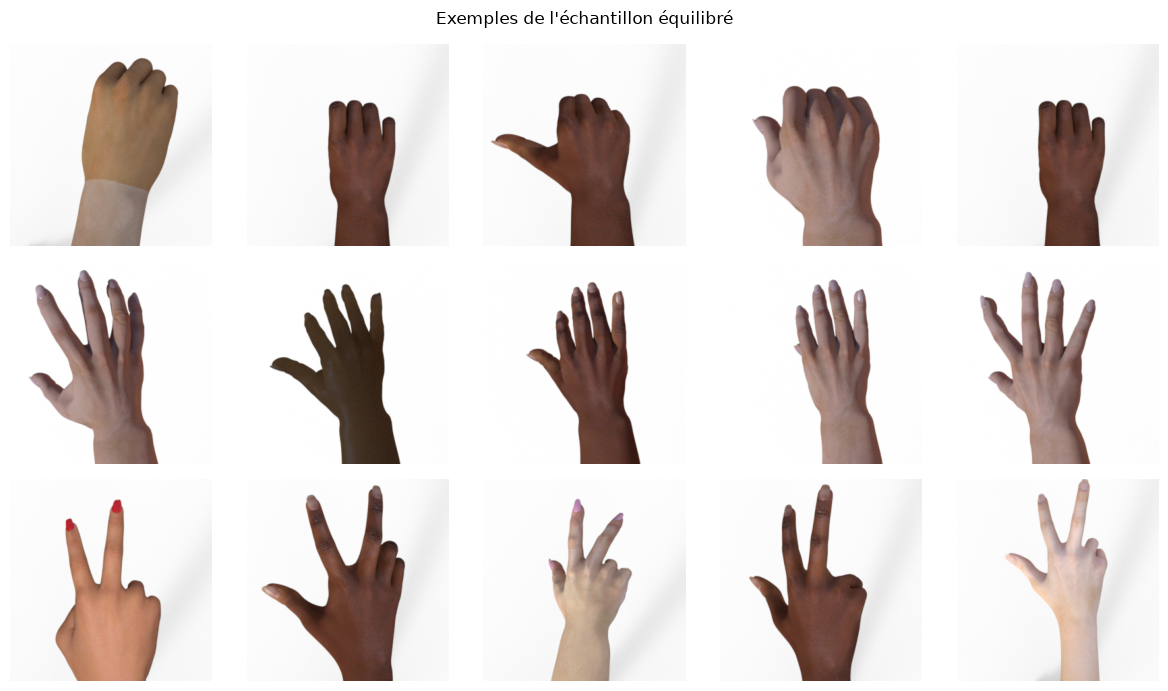

In [34]:
fig, axes = plt.subplots(3, 5, figsize=(12, 7))

for label_id in range(len(class_names)):
    indices = np.where(y_selected == label_id)[0][:5]

    for col, idx in enumerate(indices):
        axes[label_id, col].imshow(X_selected[idx])
        axes[label_id, col].axis("off")
        if col == 0:
            axes[label_id, col].set_ylabel(
                label_to_name[label_id],
                rotation=90,
                size=12
            )

plt.suptitle("Exemples de l'échantillon équilibré")
plt.tight_layout()
plt.show()

## 6. Comprendre le prétraitement

Le sujet impose deux opérations principales :

1. **Conserver le format RGB** : trois canaux de couleur.
2. **Redimensionner chaque image en 32 × 32 pixels**.

### Pourquoi redimensionner ?

Les images originales peuvent avoir des dimensions différentes. Or, les modèles attendent généralement des entrées de dimensions identiques.

Le redimensionnement donne donc à toutes les images une forme commune : `32 × 32 × 3`.

### Que signifie RGB ?

- R : intensité du rouge ;
- G : intensité du vert ;
- B : intensité du bleu.

Nous conservons les trois canaux : nous ne convertissons pas les images en niveaux de gris.

In [35]:
IMG_HEIGHT = 32
IMG_WIDTH = 32

# Redimensionnement de toutes les images.
X_resized = tf.image.resize(
    X_selected,
    size=(IMG_HEIGHT, IMG_WIDTH),
    method="bilinear"
).numpy()

print("Dimensions après redimensionnement :", X_resized.shape)
print("Type des valeurs :", X_resized.dtype)
print("Valeur minimale :", X_resized.min())
print("Valeur maximale :", X_resized.max())

Dimensions après redimensionnement : (900, 32, 32, 3)
Type des valeurs : float32
Valeur minimale : 6.8085938
Valeur maximale : 255.0


### 6.1 Comparer avant et après redimensionnement

Le redimensionnement réduit le nombre de pixels. Cela rend les entrées plus petites et uniformes, mais peut aussi supprimer certains détails fins.

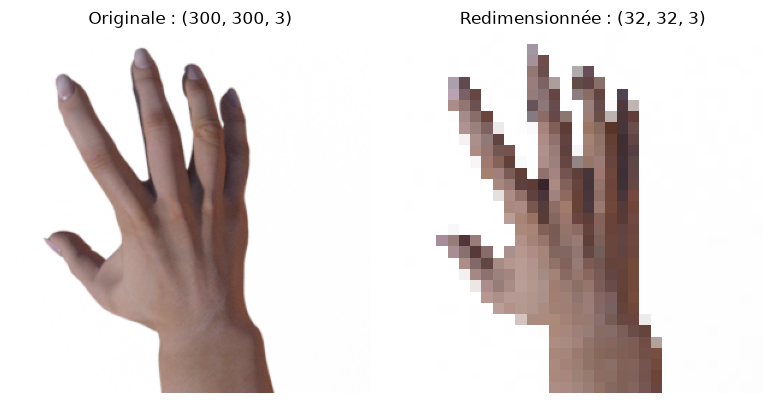

In [36]:
idx = 0

fig, axes = plt.subplots(1, 2, figsize=(8, 4))

axes[0].imshow(X_selected[idx])
axes[0].set_title(f"Originale : {X_selected[idx].shape}")
axes[0].axis("off")

axes[1].imshow(np.clip(X_resized[idx], 0, 255).astype(np.uint8))
axes[1].set_title(f"Redimensionnée : {X_resized[idx].shape}")
axes[1].axis("off")

plt.tight_layout()
plt.show()

### 6.2 Examiner les canaux RGB

Une image couleur est composée de trois matrices. Affichons-les séparément pour comprendre la représentation.

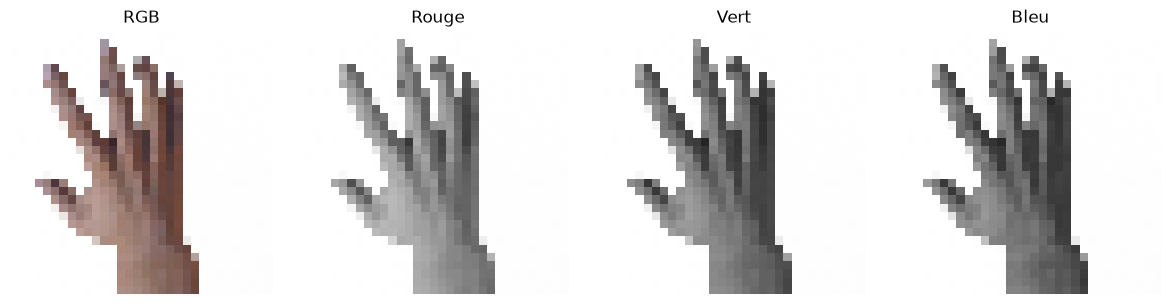

In [37]:
idx = 0
image = np.clip(X_resized[idx], 0, 255).astype(np.uint8)

fig, axes = plt.subplots(1, 4, figsize=(12, 3))
axes[0].imshow(image)
axes[0].set_title("RGB")
axes[0].axis("off")

for channel, name in enumerate(["Rouge", "Vert", "Bleu"]):
    axes[channel + 1].imshow(image[:, :, channel], cmap="gray", vmin=0, vmax=255)
    axes[channel + 1].set_title(name)
    axes[channel + 1].axis("off")

plt.tight_layout()
plt.show()

## 7. Normaliser les pixels : faut-il le faire ?

Une normalisation fréquente consiste à diviser les valeurs des pixels par 255. Les valeurs passent alors approximativement de `[0, 255]` à `[0, 1]`.

Cela peut faciliter l'optimisation de certains modèles, notamment les réseaux de neurones.

**Point important pour votre comparaison :** le sujet impose RGB et 32 × 32, mais ne précise pas explicitement la normalisation. Nous allons conserver :
- `X_resized` : valeurs dans l'échelle approximative `[0, 255]` ;
- `X_normalized` : valeurs dans `[0, 1]`.

Pour une comparaison cohérente, nous déciderons dans la suite du projet comment fournir les entrées à chaque modèle. La normalisation ne change pas les étiquettes.

In [38]:
X_normalized = X_resized.astype("float32") / 255.0

print("Avant normalisation :", X_resized.min(), "à", X_resized.max())
print("Après normalisation :", X_normalized.min(), "à", X_normalized.max())
print("Shape conservée :", X_normalized.shape)

Avant normalisation : 6.8085938 à 255.0
Après normalisation : 0.026700368 à 1.0
Shape conservée : (900, 32, 32, 3)


## 8. Créer les ensembles train, validation et test

Nous devons évaluer les modèles sur des images qu'ils n'ont pas utilisées pour apprendre.

- **Train (60 %) :** sert à apprendre les paramètres du modèle.
- **Validation (20 %) :** sert à comparer les configurations et régler les hyperparamètres.
- **Test (20 %) :** sert à estimer la performance finale sur des données non utilisées pendant l'apprentissage ou le réglage.

### Pourquoi un split stratifié ?

Un split stratifié conserve approximativement la même proportion de chaque classe dans les trois ensembles.

Nous faisons le découpage en deux étapes :
1. 60 % train et 40 % temporaire ;
2. la moitié du temporaire pour validation et l'autre moitié pour test.

La graine garantit la reproductibilité.

In [39]:
# Première étape : 60 % train, 40 % temporaire.
X_train, X_temp, y_train, y_temp = train_test_split(
    X_normalized,
    y_selected,
    test_size=0.40,
    random_state=SEED,
    stratify=y_selected
)

# Deuxième étape : diviser les 40 % restants en 20 % validation et 20 % test.
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp
)

print("Train      :", X_train.shape, y_train.shape)
print("Validation :", X_val.shape, y_val.shape)
print("Test       :", X_test.shape, y_test.shape)

Train      : (540, 32, 32, 3) (540,)
Validation : (180, 32, 32, 3) (180,)
Test       : (180, 32, 32, 3) (180,)


### 8.1 Vérifier les proportions et l'équilibre

Avec 900 images, nous devons obtenir :
- 540 images pour train ;
- 180 images pour validation ;
- 180 images pour test.

Chaque ensemble doit contenir la même proportion des trois classes.

In [40]:
def show_distribution(name, labels):
    counts = Counter(labels)
    total = len(labels)
    print(f"\n{name} : {total} images")
    for label_id, class_name in enumerate(class_names):
        count = counts[label_id]
        print(f"  {class_name:10s}: {count:3d} ({count / total:.1%})")

show_distribution("Train", y_train)
show_distribution("Validation", y_val)
show_distribution("Test", y_test)


Train : 540 images
  rock      : 180 (33.3%)
  paper     : 180 (33.3%)
  scissors  : 180 (33.3%)

Validation : 180 images
  rock      :  60 (33.3%)
  paper     :  60 (33.3%)
  scissors  :  60 (33.3%)

Test : 180 images
  rock      :  60 (33.3%)
  paper     :  60 (33.3%)
  scissors  :  60 (33.3%)


## 9. Vérifications finales

Avant de passer à l'entraînement, vérifions les propriétés essentielles :
- 900 images au total ;
- trois classes équilibrées ;
- dimensions `32 × 32 × 3` ;
- trois canaux RGB ;
- aucune image partagée entre les ensembles, puisque le découpage est effectué à partir d'indices distincts.

Les assertions interrompent le notebook si une condition n'est pas respectée.

In [41]:
assert len(X_train) == 540
assert len(X_val) == 180
assert len(X_test) == 180

assert X_train.shape[1:] == (32, 32, 3)
assert X_val.shape[1:] == (32, 32, 3)
assert X_test.shape[1:] == (32, 32, 3)

assert len(y_train) + len(y_val) + len(y_test) == 900
assert set(np.unique(y_selected)) == set(range(len(class_names)))

for labels in [y_train, y_val, y_test]:
    assert all(np.sum(labels == i) == len(labels) // 3 for i in range(3))

print("Toutes les vérifications sont réussies.")

Toutes les vérifications sont réussies.


## 10. Comprendre ce que nous avons préparé

À ce stade, nous disposons de trois ensembles :

| Ensemble | Nombre d'images | Utilisation |
|---|---:|---|
| Train | 540 | Apprentissage |
| Validation | 180 | Choix/réglage du modèle |
| Test | 180 | Évaluation finale |

Chaque image possède une forme `32 × 32 × 3` et des valeurs de pixels normalisées entre 0 et 1.

### Pourquoi ne pas entraîner les modèles maintenant ?

Avant l'entraînement, il faut comprendre comment chaque algorithme attend ses données :
- k-NN compare généralement des vecteurs, donc les images seront aplaties (`flatten`) ;
- Softmax linéaire utilise également un vecteur de caractéristiques ;
- CNN reçoit les images sous forme de tenseurs 3D (hauteur, largeur, canaux).

Le prochain notebook ou la prochaine étape portera sur cette différence, notamment sur la perte d'information spatiale provoquée par le flattening.

---

## 11. Questions de compréhension

Répondez avec vos propres mots avant de poursuivre.

1. Pourquoi faut-il équilibrer les classes ?
2. Pourquoi redimensionne-t-on les images en `32 × 32` ?
3. Que représentent les trois canaux d'une image RGB ?
4. Quelle est la différence entre redimensionner et normaliser ?
5. À quoi servent train, validation et test ?
6. Pourquoi le split doit-il être stratifié ?
7. Pourquoi ne faut-il pas utiliser les données de test pour régler les hyperparamètres ?

**À retenir :** le prétraitement transforme les données brutes en entrées cohérentes pour les algorithmes. Il ne doit pas modifier les labels ni introduire d'information provenant du jeu de test dans l'apprentissage.
